# Does Money Win Games? Positional Spending vs. Success Across the NFL (2016-2025)

**GitHub:** https://github.com/wilska1-stack/CSC-366

## 1. The question

Every NFL team has to fit its roster under the same salary cap, so each dollar spent on
one position is a dollar not spent somewhere else. This project asks:

> **Which position groups does NFL spending affect most when it comes to winning?**
> Does a team that spends heavily on quarterbacks or the offensive line win more than a
> team that spends heavily on defensive backs?

If some positions show a stronger link between spending and wins, those positions give
teams the best return. If spending barely relates to wins, that is a finding too.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.width", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

# Chart style: light surface, recessive grid, one accent color
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
})

POSITIONS = ["quarterback", "offensive_line", "running_back", "wide_receiver",
             "tight_end", "defensive_line", "linebackers", "defensive_backs"]
LABEL = {"quarterback": "Quarterback", "offensive_line": "Offensive line",
         "running_back": "Running back", "wide_receiver": "Wide receiver",
         "tight_end": "Tight end", "defensive_line": "Defensive line",
         "linebackers": "Linebackers", "defensive_backs": "Defensive backs"}

## 2. The data

The data was collected by `scrape_nfl_data.py` from three public sources:

| Source | What it gives |
|---|---|
| Over the Cap | Cap spending (US dollars) for all 32 teams each season, by position group |
| ESPN standings API | Regular-season wins for each team and season |
| nflverse | Player rosters (used for roster counts by position) |

Each row is one team in one season: 32 teams x 10 seasons = 320 rows.

In [2]:
raw = pd.read_csv("nfl_positional_spending_2016_2025.csv")
print(raw.shape)
raw[["year", "team", "quarterback", "offensive_line", "total_amount_spent",
     "total_wins"]].head()

(320, 21)


,year,team,quarterback,offensive_line,total_amount_spent,total_wins
0,2016,Dallas Cowboys,23926148,21408752,144089272,13
1,2016,Washington Commanders,22237334,26070817,126732626,8
2,2016,Pittsburgh Steelers,25334805,28392364,137763362,11
3,2016,New England Patriots,15259305,26847155,127922694,14
4,2016,Los Angeles Chargers,17180000,25663138,140149243,5


## 3. Cleaning and preprocessing

### 3.1 Missing values, duplicates, and coverage

In [3]:
df = raw.copy()
df["team"] = df["team"].str.strip()
df = df.sort_values(["year", "team"]).reset_index(drop=True)

print("Missing values:          ", df.isnull().sum().sum())
print("Duplicate team-seasons:  ", df.duplicated(["year", "team"]).sum())
print("Distinct teams:          ", df["team"].nunique())
print("Teams per season:        ", df.groupby("year").size().unique())
print("Negative dollar amounts: ", (df[POSITIONS] < 0).sum().sum())
print("Total = sum of 8 groups: ",
      (df["total_amount_spent"] == df[POSITIONS].sum(axis=1)).all())

Missing values:           0
Duplicate team-seasons:   0
Distinct teams:           32
Teams per season:         [32]
Negative dollar amounts:  0
Total = sum of 8 groups:  True


The data has no missing values or duplicates, and every team appears once in every
season. The scraper already renamed relocated teams (e.g. *Oakland Raiders* became
*Las Vegas Raiders*), so each franchise has one name across all ten seasons.

`total_amount_spent` is exactly the sum of the 8 position groups, so it leaves out
kickers, punters, long snappers and fullbacks.

### 3.2 Wins: the season got longer

The NFL played 16 games through 2020 and 17 from 2021 on, so 12 wins in 2018 is not the
same as 12 wins in 2024. I convert wins to **win percentage**. Buffalo and Cincinnati
only played 16 games in 2022 because their game was cancelled.

In [4]:
df["games_played"] = np.where(df["year"] <= 2020, 16, 17)
cancelled = (df["year"] == 2022) & df["team"].isin(["Buffalo Bills", "Cincinnati Bengals"])
df.loc[cancelled, "games_played"] = 16
df["win_pct"] = df["total_wins"] / df["games_played"]

# Every game produces one win unless it is a tie, so (games / 2) - wins = ties
season = df.groupby("year").agg(wins=("total_wins", "sum"),
                                games=("games_played", "sum"))
season["games"] = season["games"] // 2
season["implied_ties"] = season["games"] - season["wins"]
season.T

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
wins,254,256,254,255,255,271,269,272,272,271
games,256,256,256,256,256,272,271,272,272,272
implied_ties,2,0,2,1,1,1,2,0,0,1


The win totals are consistent: in every season, total wins equal the number of games
minus the number of tied games. The scraper did not save ties, so `win_pct` counts the
10 tied games across the decade as losses. That changes a team's win % by at most
about 0.03, so the effect on the analysis is small.

### 3.3 Spending: the salary cap kept growing

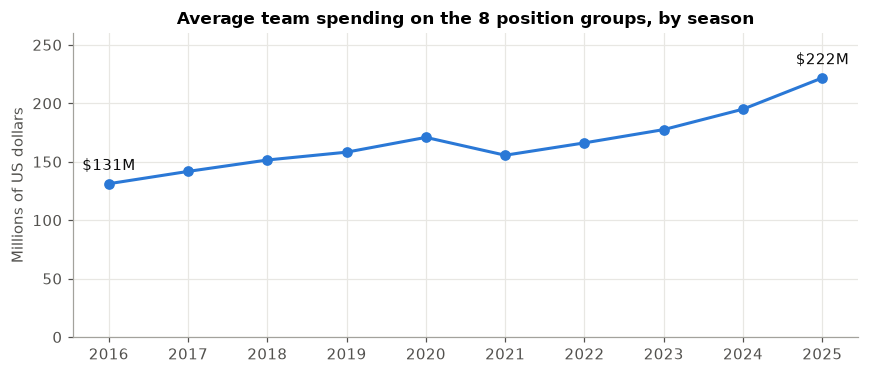

In [5]:
avg_total = df.groupby("year")["total_amount_spent"].mean() / 1e6

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(avg_total.index, avg_total.values, color=BLUE, lw=2, marker="o", ms=6)
for y in (2016, 2025):
    ax.annotate(f"${avg_total[y]:.0f}M", (y, avg_total[y]), textcoords="offset points",
                xytext=(0, 9), ha="center", color="#0b0b0b")
ax.set_title("Average team spending on the 8 position groups, by season")
ax.set_ylabel("Millions of US dollars")
ax.set_ylim(0, 260)
ax.set_xticks(avg_total.index)
plt.tight_layout()
plt.show()

Average spending rose about 70% between 2016 and 2025, so raw dollars from different
seasons can't be compared. (The dip in 2021 is the COVID-related cap drop.) I add two
adjusted versions of each position's spending:

* **Share** (`<position>_share`): the fraction of the team's spending that went to that
  position. This measures *how a team split its money*.
* **Z-score within the season** (`<position>_z`): how many standard deviations above
  or below that season's league average the team spent. This measures *how much a team
  spent compared with other teams that year*.

In [6]:
for p in POSITIONS:
    df[f"{p}_share"] = df[p] / df["total_amount_spent"]
    by_year = df.groupby("year")[p]
    df[f"{p}_z"] = (df[p] - by_year.transform("mean")) / by_year.transform("std")
by_year = df.groupby("year")["total_amount_spent"]
df["total_spent_z"] = ((df["total_amount_spent"] - by_year.transform("mean"))
                       / by_year.transform("std"))

print("Shares add to 1 in every row:",
      np.allclose(df[[f"{p}_share" for p in POSITIONS]].sum(axis=1), 1))

Shares add to 1 in every row: True


### 3.4 Outliers

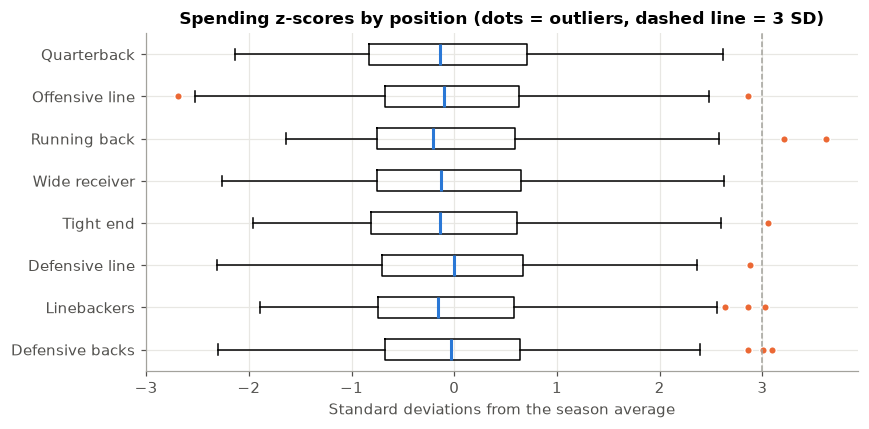

7 team-seasons have a position more than 3 SD from its season mean:
  2017 Carolina Panthers        Linebackers     z = 3.02
  2019 Baltimore Ravens         Defensive backs z = 3.10
  2022 Dallas Cowboys           Running back    z = 3.22
  2022 New England Patriots     Tight end       z = 3.06
  2023 Buffalo Bills            Defensive backs z = 3.01
  2024 Chicago Bears            Linebackers     z = 3.03
  2024 New Orleans Saints       Running back    z = 3.62


In [7]:
z_cols = [f"{p}_z" for p in POSITIONS]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df[c] for c in z_cols], orientation="horizontal", widths=0.5,
           tick_labels=[LABEL[p] for p in POSITIONS],
           medianprops=dict(color=BLUE, lw=2),
           flierprops=dict(marker="o", ms=5, mfc=ORANGE, mec="white"))
ax.axvline(3, color=GRAY, ls="--", lw=1)
ax.set_title("Spending z-scores by position (dots = outliers, dashed line = 3 SD)")
ax.set_xlabel("Standard deviations from the season average")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

extreme = df[(df[z_cols].abs() > 3).any(axis=1)]
print(f"{len(extreme)} team-seasons have a position more than 3 SD from its season mean:")
for _, row in extreme.iterrows():
    col = max(z_cols, key=lambda c: abs(row[c]))
    print(f"  {row.year} {row.team:24s} {LABEL[col[:-2]]:15s} z = {row[col]:.2f}")

The outliers are real contracts, not data errors: one team paying a star at a position
where most teams spend little, such as the 2024 Saints at running back. Since big contracts are exactly what
this project studies, **I keep them** and only flag them. Removing them would remove
the teams that made the most extreme spending choices.

### 3.5 Roster counts

In [8]:
q1, q3 = df["roster_total_players"].quantile([0.25, 0.75])
cutoff = q1 - 1.5 * (q3 - q1)
df["roster_count_low"] = df["roster_total_players"] < cutoff
print(f"Low-roster cutoff (Q1 - 1.5 x IQR): {cutoff:.1f} players")
df.loc[df["roster_count_low"], ["year", "team", "roster_total_players"]]

Low-roster cutoff (Q1 - 1.5 x IQR): 77.0 players


,year,team,roster_total_players
4,2016,Carolina Panthers,76
9,2016,Denver Broncos,70
18,2016,Los Angeles Rams,70
27,2016,San Francisco 49ers,76
31,2016,Washington Commanders,75


All five unusually small rosters are from 2016, which points to incomplete 2016 data
in nflverse rather than real roster differences. The roster counts are not used in the
main analysis, so these rows are flagged and kept.

## 4. Summary statistics

In [9]:
summary = pd.DataFrame({
    "Mean ($M)":   df[POSITIONS].mean() / 1e6,
    "Median ($M)": df[POSITIONS].median() / 1e6,
    "Min ($M)":    df[POSITIONS].min() / 1e6,
    "Max ($M)":    df[POSITIONS].max() / 1e6,
    "Avg share":   [df[f"{p}_share"].mean() for p in POSITIONS],
}).rename(index=LABEL).sort_values("Mean ($M)", ascending=False)
summary.style.format({c: "${:.1f}" for c in summary.columns[:4]} | {"Avg share": "{:.1%}"})

,Mean ($M),Median ($M),Min ($M),Max ($M),Avg share
Defensive line,$37.9,$37.6,$10.8,$82.4,22.6%
Offensive line,$33.1,$31.8,$6.3,$87.7,19.8%
Defensive backs,$28.5,$27.8,$9.3,$62.6,17.2%
Wide receiver,$19.6,$18.3,$3.1,$51.5,11.7%
Quarterback,$18.6,$17.1,$1.3,$52.9,11.1%
Linebackers,$12.6,$11.8,$1.9,$34.2,7.6%
Tight end,$9.0,$8.0,$1.0,$27.6,5.4%
Running back,$7.6,$6.9,$1.5,$22.8,4.6%


In [10]:
print("Team-seasons:", len(df), "| Teams:", df["team"].nunique(),
      "| Seasons:", df["year"].min(), "-", df["year"].max())
print(f"Win %:  mean {df.win_pct.mean():.3f}, median {df.win_pct.median():.3f}, "
      f"min {df.win_pct.min():.3f}, max {df.win_pct.max():.3f}, SD {df.win_pct.std():.3f}")
print(f"Wins:   range {df.total_wins.min()} - {df.total_wins.max()}")

Team-seasons: 320 | Teams: 32 | Seasons: 2016 - 2025
Win %:  mean 0.498, median 0.500, min 0.000, max 0.882, SD 0.192
Wins:   range 0 - 15


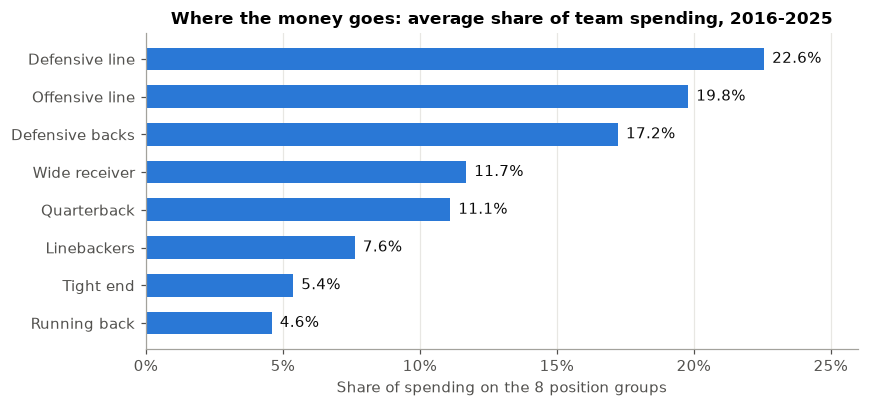

In [11]:
shares = summary["Avg share"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(shares.index, shares.values, color=BLUE, height=0.6)
for i, v in enumerate(shares.values):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", color="#0b0b0b")
ax.set_title("Where the money goes: average share of team spending, 2016-2025")
ax.set_xlim(0, 0.26)
ax.set_xlabel("Share of spending on the 8 position groups")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Teams put the most money into the two lines: the defensive line (about 23%) and the
offensive line (about 20%), followed by defensive backs. Running backs and tight ends
get the least.

## 5. Exploratory analysis

### 5.1 How win % is spread out

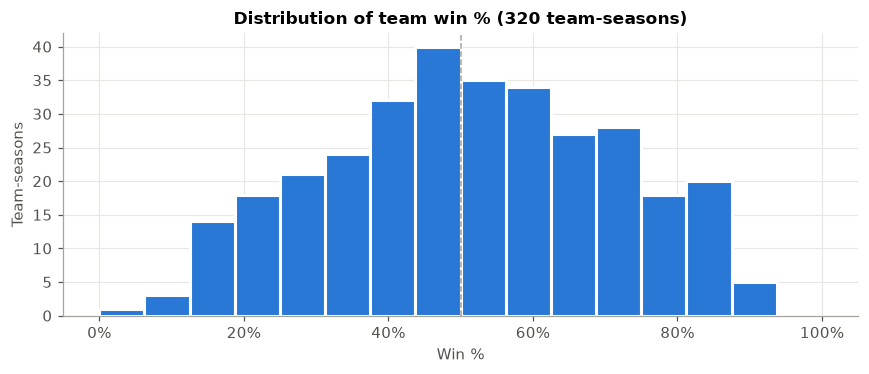

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["win_pct"], bins=np.arange(0, 1.0001, 0.0625), color=BLUE,
        edgecolor="white", linewidth=2)
ax.axvline(0.5, color=GRAY, ls="--", lw=1)
ax.set_title("Distribution of team win % (320 team-seasons)")
ax.set_xlabel("Win %")
ax.set_ylabel("Team-seasons")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.show()

Win % is roughly bell-shaped and centered on 50%, since every win is someone else's
loss. Most seasons fall between about 20% and 80%, with a few near-winless seasons
(the 2017 Browns went 0-16).

### 5.2 Best and worst teams over the decade

In [13]:
team = df.groupby("team").agg(
    win_pct=("win_pct", "mean"),
    total_spent_z=("total_spent_z", "mean"),
    qb_share=("quarterback_share", "mean"),
).sort_values("win_pct", ascending=False)
pd.concat([team.head(5), team.tail(5)]).style.format(
    {"win_pct": "{:.1%}", "total_spent_z": "{:+.2f}", "qb_share": "{:.1%}"})

,win_pct,total_spent_z,qb_share
team,,,
Kansas City Chiefs,71.6%,+0.53,12.0%
Buffalo Bills,63.9%,-0.11,9.5%
Baltimore Ravens,62.5%,-0.10,13.1%
Pittsburgh Steelers,61.4%,+0.23,12.5%
Seattle Seahawks,61.3%,-0.23,13.5%
Carolina Panthers,37.1%,-0.44,11.5%
Arizona Cardinals,37.0%,+0.10,11.9%
Cleveland Browns,35.6%,-0.26,10.8%
New York Giants,33.4%,-0.42,11.5%


Kansas City won 72% of its games over the decade; the Jets won under 30%. The top and
bottom teams don't split cleanly by spending, which is a first hint that money alone
doesn't explain winning.

### 5.3 Does spending more overall go with winning more?

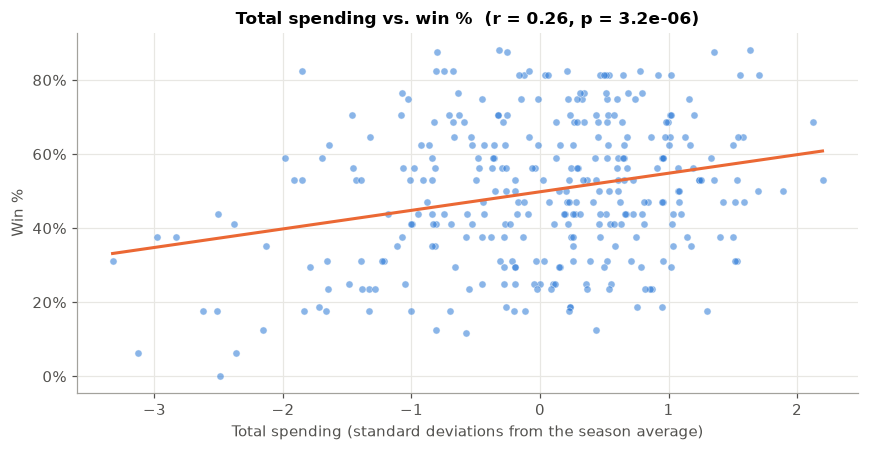

Each 1 SD of extra total spending goes with +0.050 win %, about +0.9 wins in a 17-game season.


In [14]:
r, p = stats.pearsonr(df["total_spent_z"], df["win_pct"])
slope, intercept = np.polyfit(df["total_spent_z"], df["win_pct"], 1)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df["total_spent_z"], df["win_pct"], s=22, color=BLUE, alpha=0.55,
           edgecolor="white", linewidth=0.5)
xs = np.linspace(df["total_spent_z"].min(), df["total_spent_z"].max(), 50)
ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2)
ax.set_title(f"Total spending vs. win %  (r = {r:.2f}, p = {p:.1e})")
ax.set_xlabel("Total spending (standard deviations from the season average)")
ax.set_ylabel("Win %")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.show()
print(f"Each 1 SD of extra total spending goes with {slope:+.3f} win %, "
      f"about {slope * 17:+.1f} wins in a 17-game season.")

There is a real but modest positive relationship: teams that spend more than other
teams that season tend to win more, but the points are widely scattered.

## 6. Statistical analysis: which positions matter?

### 6.1 Correlation of each position's spending with win %

For each position I test two things against win %: the **z-score** (spending more than
other teams) and the **share** (putting a bigger slice of the budget there). Pearson
correlation, 320 team-seasons; p < 0.05 is treated as significant.

In [15]:
rows = []
for p_ in POSITIONS:
    rz, pz = stats.pearsonr(df[f"{p_}_z"], df["win_pct"])
    rs, ps = stats.pearsonr(df[f"{p_}_share"], df["win_pct"])
    rows.append({"position": LABEL[p_], "r (z-score)": rz, "p (z-score)": pz,
                 "r (share)": rs, "p (share)": ps})
corr = pd.DataFrame(rows).set_index("position").sort_values("r (z-score)", ascending=False)
corr.style.format("{:+.3f}", subset=["r (z-score)", "r (share)"]) \
    .format("{:.3f}", subset=["p (z-score)", "p (share)"])

,r (z-score),p (z-score),r (share),p (share)
position,,,,
Tight end,+0.124,0.026,+0.075,0.183
Quarterback,+0.113,0.043,+0.071,0.206
Defensive line,+0.108,0.054,+0.033,0.562
Defensive backs,+0.082,0.141,-0.006,0.913
Wide receiver,+0.057,0.312,-0.003,0.953
Offensive line,+0.044,0.431,-0.073,0.190
Running back,+0.011,0.839,-0.049,0.380
Linebackers,+0.008,0.886,-0.072,0.202


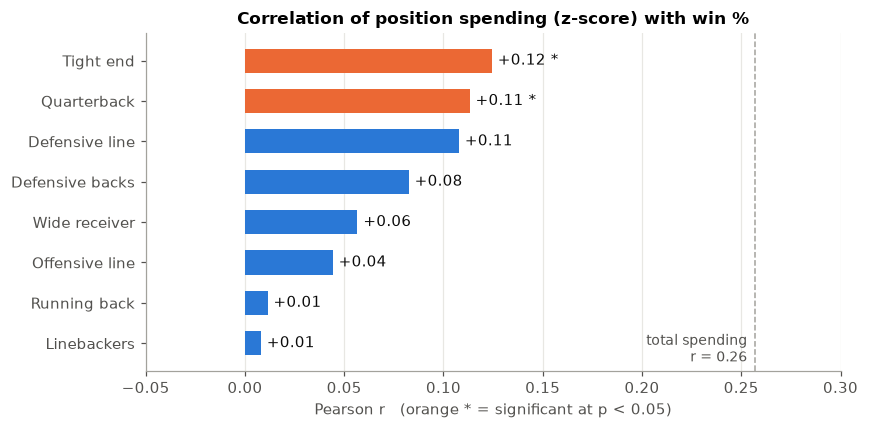

In [16]:
plot = corr["r (z-score)"].sort_values()
colors = [ORANGE if corr.loc[i, "p (z-score)"] < 0.05 else BLUE for i in plot.index]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(plot.index, plot.values, color=colors, height=0.6)
for i, (name, v) in enumerate(plot.items()):
    star = " *" if corr.loc[name, "p (z-score)"] < 0.05 else ""
    ax.text(v + 0.003, i, f"{v:+.2f}{star}", va="center", color="#0b0b0b")
ax.axvline(r, color=GRAY, ls="--", lw=1)
ax.text(r - 0.004, -0.45, f"total spending\nr = {r:.2f}", color="#52514e", fontsize=9, ha="right")
ax.set_title("Correlation of position spending (z-score) with win %")
ax.set_xlabel("Pearson r   (orange * = significant at p < 0.05)")
ax.set_xlim(-0.05, 0.3)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Every position's correlation is weak (r ≤ 0.13), and all are smaller than total
spending's r = 0.26. Quarterback and tight end are the only individually significant
positions, with defensive line just missing (p ≈ 0.05).

The **share** correlations are all close to zero and none are significant. Across this
decade, *how* a team divided its budget had almost no relationship with winning.

### 6.2 Multiple regression: all positions at once

Single correlations can be misleading because spending on different positions moves
together. This regression estimates each position's link with win % while holding the
others fixed. Standard errors are clustered by team, because the same franchise
appears ten times.

In [17]:
formula = "win_pct ~ " + " + ".join(f"{p_}_z" for p_ in POSITIONS)
model = smf.ols(formula, df).fit(cov_type="cluster",
                                  cov_kwds={"groups": pd.factorize(df["team"])[0]})
coef = pd.DataFrame({"coef": model.params, "low": model.conf_int()[0],
                     "high": model.conf_int()[1], "p": model.pvalues}).drop("Intercept")
coef.index = [LABEL[i[:-2]] for i in coef.index]
coef["wins per 17 games"] = coef["coef"] * 17
print(f"R-squared: {model.rsquared:.3f}   (n = {int(model.nobs)})")
coef.sort_values("coef", ascending=False)

R-squared: 0.070   (n = 320)


,coef,low,high,p,wins per 17 games
Quarterback,0.033,0.011,0.055,0.004,0.555
Defensive line,0.028,0.004,0.052,0.021,0.483
Tight end,0.025,0.004,0.046,0.019,0.429
Defensive backs,0.023,0.000,0.046,0.047,0.397
Offensive line,0.016,-0.004,0.036,0.120,0.268
Wide receiver,0.015,-0.008,0.038,0.187,0.263
Running back,0.010,-0.013,0.033,0.381,0.175
Linebackers,0.006,-0.017,0.029,0.601,0.106


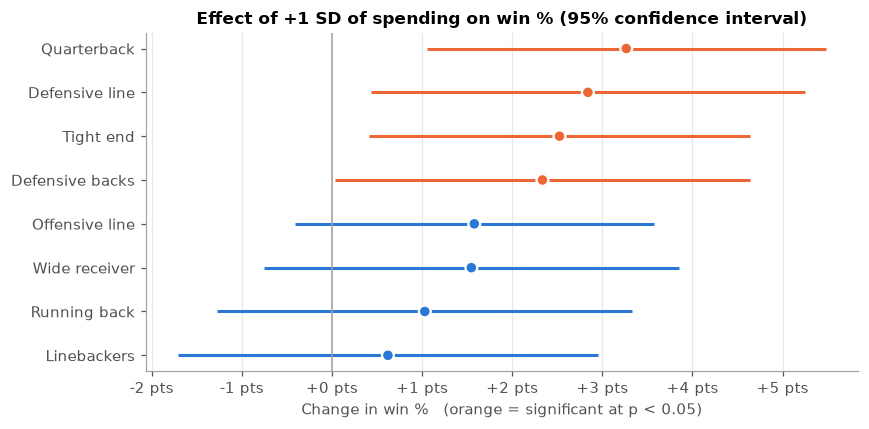

In [18]:
c = coef.sort_values("coef")
colors = [ORANGE if pv < 0.05 else BLUE for pv in c["p"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hlines(range(len(c)), c["low"], c["high"], color=colors, lw=2)
ax.scatter(c["coef"], range(len(c)), color=colors, s=60, zorder=3,
           edgecolor="white", linewidth=1.5)
ax.axvline(0, color=GRAY, lw=1)
ax.set_yticks(range(len(c)), c.index)
ax.set_title("Effect of +1 SD of spending on win % (95% confidence interval)")
ax.set_xlabel("Change in win %   (orange = significant at p < 0.05)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:+.0f} pts"))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Holding the other positions fixed, **quarterback, defensive line, tight end and
defensive back** spending have significant positive effects (defensive backs only just,
p ≈ 0.047). Offensive line, wide receiver, running back and linebacker spending do not.
The quarterback effect is the largest: one standard deviation more QB spending goes
with about 3 percentage points more win %, roughly half a win per season.

The model's R² is only about 0.07: spending explains about 7% of the variation in win
%. The other 93% comes from things salary doesn't capture, such as coaching, injuries,
draft hits and luck.

### 6.3 Quarterback spending tiers

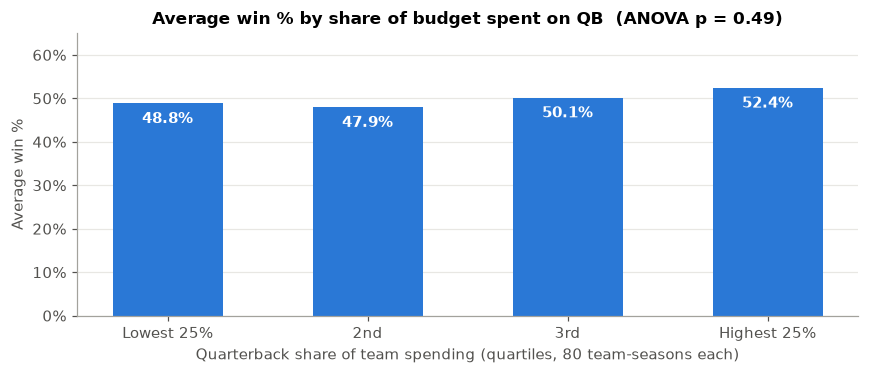

In [19]:
df["qb_tier"] = pd.qcut(df["quarterback_share"], 4,
                        labels=["Lowest 25%", "2nd", "3rd", "Highest 25%"])
tiers = df.groupby("qb_tier", observed=True)["win_pct"].agg(["mean", "count"])
f_stat, p_anova = stats.f_oneway(*[g["win_pct"] for _, g in df.groupby("qb_tier", observed=True)])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(tiers.index.astype(str), tiers["mean"], color=BLUE, width=0.55)
for i, v in enumerate(tiers["mean"]):
    ax.text(i, v - 0.045, f"{v:.1%}", ha="center", color="white", fontweight="bold")
ax.set_ylim(0, 0.65)
ax.set_title(f"Average win % by share of budget spent on QB  (ANOVA p = {p_anova:.2f})")
ax.set_xlabel("Quarterback share of team spending (quartiles, 80 team-seasons each)")
ax.set_ylabel("Average win %")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Teams in the top quarter of QB spending won about 52% of their games versus about 49%
for the bottom quarter. The difference points the same way as the regression but is
small, and the ANOVA test does not find it significant.

### 6.4 Ten-year averages by team (the comparison from the proposal)

The proposal planned to average each team over the 10 seasons and compare those
averages. With only 32 teams this test has much less power, so I use Spearman rank
correlation, which is less sensitive to a single unusual team.

In [20]:
avg = df.groupby("team")[[f"{p_}_share" for p_ in POSITIONS] + ["win_pct"]].mean()
rows = []
for p_ in POSITIONS:
    rho, pv = stats.spearmanr(avg[f"{p_}_share"], avg["win_pct"])
    rows.append({"position": LABEL[p_], "Spearman rho": rho, "p": pv})
team_corr = (pd.DataFrame(rows).set_index("position")
             .sort_values("Spearman rho", ascending=False))
team_corr.style.format({"Spearman rho": "{:+.3f}", "p": "{:.3f}"})

,Spearman rho,p
position,,
Tight end,+0.350,0.050
Quarterback,+0.283,0.117
Defensive line,+0.219,0.228
Defensive backs,-0.014,0.940
Linebackers,-0.131,0.474
Wide receiver,-0.247,0.172
Running back,-0.311,0.083
Offensive line,-0.375,0.034


Over ten years, teams that gave the **offensive line** a bigger share of the budget
had *worse* records (rho ≈ -0.38, p ≈ 0.03), the only result below p = 0.05. Tight end
share leans positive (rho ≈ +0.35, p ≈ 0.05) and running back share leans negative,
but with only 32 data points none of the other relationships are reliable.

A likely explanation for the offensive line result: struggling teams often draft or
sign expensive linemen to rebuild, so heavy line spending may follow losing rather
than cause it.

## 7. Findings and why they matter

**What I asked:** which position groups does NFL spending affect most when it comes to
winning?

**What I found:**

1. **Spending more overall helps, a little.** Teams that out-spend the rest of the
   league that season win more (r = 0.26), but spending explains only about 7% of the
   differences in win %.
2. **Quarterback and defensive line spending matter most.** In the regression,
   quarterback, defensive line, tight end and defensive back spending have significant
   positive effects. Quarterback is the largest: about half an extra win per season
   for one standard deviation more spending. Offensive line spending, the
   second-biggest budget item, shows no significant benefit.
3. **How the budget is split barely matters.** None of the share-of-budget measures is
   significantly related to win % across the 320 team-seasons. Shifting money from one
   position to another, on its own, doesn't show up in the standings.

**Why it matters:** with a hard salary cap, teams constantly debate where to spend. This
data suggests there is no position that buys wins reliably. The edge, where there is
one, comes from paying for quality at quarterback and on the defensive line, and from things
money doesn't measure: drafting, coaching and player development. That last point is
also why the effects are small. A team with a great quarterback on a cheap rookie
contract wins without the spending showing up in this data.

**Limitations:**

* **Correlation is not causation.** Good teams often pay their players *because* they
  played well (extensions after winning), which could make spending look more useful
  than it is.
* **Rookie contracts hide value.** Stars on rookie deals are cheap, so spending
  understates the talent of some of the best teams.
* **Ties count as losses** in win %, because the scraper did not save ties
  (10 games across ten seasons).
* **Spending is cap spending by position**, not total payroll: dead money and
  special teams are not included.

**GitHub:** https://github.com/wilska1-stack/CSC-366